In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

os.makedirs("results", exist_ok=True)

In [2]:
df = pd.read_csv("data/breast_cancer_data.csv")
df = df.drop(columns=["Unnamed: 32", "id"])
df["diagnosis_int"] = (df["diagnosis"] == "M").astype(int)
df = df.drop(columns=["diagnosis"])

X = df.drop(columns=["diagnosis_int"])
Y = df["diagnosis_int"]

print(X.shape)
print(Y.value_counts())

(569, 30)
diagnosis_int
0    357
1    212
Name: count, dtype: int64


In [3]:
class CorrelationSelector(BaseEstimator, TransformerMixin):
    # keeps features that are correlated with the target,
    # then drops features that are almost the same as one already kept

    def __init__(self, target_threshold=0.2, redundancy_threshold=0.9):
        self.target_threshold = target_threshold
        self.redundancy_threshold = redundancy_threshold

    def fit(self, X, y):
        X = pd.DataFrame(X)
        y = pd.Series(np.asarray(y), index=X.index)

        target_corr = X.corrwith(y).abs()
        candidates = target_corr[target_corr > self.target_threshold]
        candidates = candidates.sort_values(ascending=False).index

        feature_corr = X.corr().abs()
        kept = []
        for col in candidates:
            if all(feature_corr.loc[col, k] < self.redundancy_threshold for k in kept):
                kept.append(col)

        self.support_ = np.array([c in kept for c in X.columns])
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]

    def get_support(self):
        return self.support_

In [4]:
def mi_score(X, y):
    # fixed random_state so mutual information gives the same result every run
    return mutual_info_classif(X, y, random_state=42)


def make_forest():
    return RandomForestClassifier(criterion="entropy", random_state=47)


selectors = {
    "All features": "passthrough",
    "Correlation filter": CorrelationSelector(),
    "F-test (k=20)": SelectKBest(f_classif, k=20),
    "Mutual info (k=20)": SelectKBest(mi_score, k=20),
    "RFE (20)": RFE(make_forest(), n_features_to_select=20, step=2),
    "Feature importance": SelectFromModel(make_forest(), threshold=0.013),
    "L1 (LinearSVC)": SelectFromModel(LinearSVC(C=1, penalty="l1", dual=False, max_iter=5000)),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

In [5]:
rows = []
selection_counts = {}

for name, selector in selectors.items():
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("select", selector),
        ("model", make_forest()),
    ])
    scores = cross_validate(
        pipe, X, Y, cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
        return_estimator=True,
    )

    if selector == "passthrough":
        masks = [np.ones(X.shape[1], dtype=bool) for _ in scores["estimator"]]
    else:
        masks = [est.named_steps["select"].get_support() for est in scores["estimator"]]

    selection_counts[name] = pd.Series(np.sum(masks, axis=0), index=X.columns)

    rows.append({
        "method": name,
        "avg_features": np.mean([m.sum() for m in masks]),
        "accuracy": scores["test_accuracy"].mean(),
        "f1": scores["test_f1"].mean(),
        "f1_std": scores["test_f1"].std(),
        "roc_auc": scores["test_roc_auc"].mean(),
    })
    print("done:", name)

results = pd.DataFrame(rows).set_index("method").round(4)
results = results.sort_values("f1", ascending=False)
results.to_csv("results/cv_results.csv")
print(results.to_string())

done: All features
done: Correlation filter
done: F-test (k=20)
done: Mutual info (k=20)
done: RFE (20)
done: Feature importance
done: L1 (LinearSVC)
                    avg_features  accuracy      f1  f1_std  roc_auc
method                                                             
L1 (LinearSVC)           19.0667    0.9613  0.9473  0.0212   0.9922
Mutual info (k=20)       20.0000    0.9613  0.9471  0.0292   0.9891
Feature importance       15.4667    0.9596  0.9453  0.0197   0.9905
F-test (k=20)            20.0000    0.9590  0.9440  0.0248   0.9900
RFE (20)                 20.0000    0.9590  0.9434  0.0322   0.9901
Correlation filter       15.8667    0.9584  0.9428  0.0257   0.9929
All features             30.0000    0.9572  0.9410  0.0310   0.9902


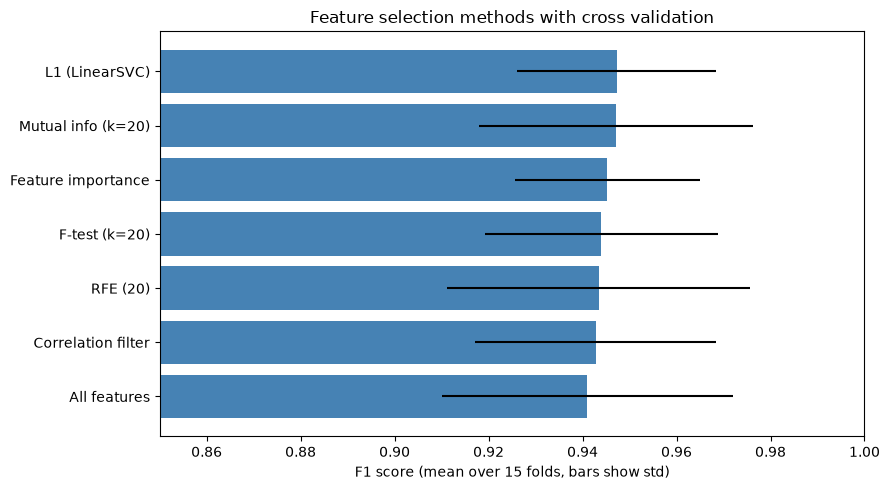

In [6]:
plt.figure(figsize=(9, 5))
plt.barh(results.index, results["f1"], xerr=results["f1_std"], color="steelblue")
plt.xlim(0.85, 1.0)
plt.xlabel("F1 score (mean over 15 folds, bars show std)")
plt.title("Feature selection methods with cross validation")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("results/f1_by_method.png")
plt.show()

In [7]:
freq = pd.DataFrame(selection_counts)
always_picked = (freq == 15).sum()
print("features picked in all 15 folds:")
print(always_picked.to_string())

features picked in all 15 folds:
All features          30
Correlation filter    14
F-test (k=20)         19
Mutual info (k=20)    18
RFE (20)              15
Feature importance    14
L1 (LinearSVC)         6


In [8]:
ks = [5, 10, 15, 20, 25, 30]
curve = {"F-test": [], "Mutual info": []}

for k in ks:
    for label, func in [("F-test", f_classif), ("Mutual info", mi_score)]:
        pipe = Pipeline([
            ("scale", StandardScaler()),
            ("select", SelectKBest(func, k=k)),
            ("model", make_forest()),
        ])
        scores = cross_validate(pipe, X, Y, cv=cv, scoring="f1")
        curve[label].append(scores["test_score"].mean())

curve_df = pd.DataFrame(curve, index=ks).round(4)
curve_df.index.name = "k"
curve_df.to_csv("results/k_curve.csv")
print(curve_df)

    F-test  Mutual info
k                      
5   0.9173       0.9154
10  0.9304       0.9344
15  0.9303       0.9303
20  0.9440       0.9471
25  0.9464       0.9480
30  0.9410       0.9410


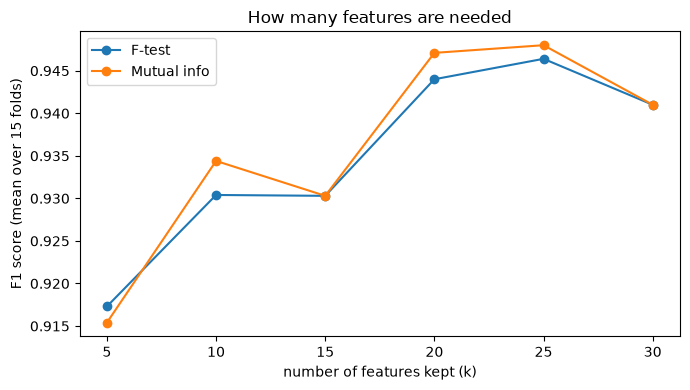

In [9]:
plt.figure(figsize=(7, 4))
for label in curve_df.columns:
    plt.plot(curve_df.index, curve_df[label], marker="o", label=label)
plt.xlabel("number of features kept (k)")
plt.ylabel("F1 score (mean over 15 folds)")
plt.title("How many features are needed")
plt.legend()
plt.tight_layout()
plt.savefig("results/f1_vs_k.png")
plt.show()